# A Cloud–Local Hybrid Chatbot: Intelligence and Hardware Trade-offs

**Measuring what a System-1 router buys you when a small on-device model and a
large cloud model are both available.**

---

## Abstract

Deploying a large language model in the cloud is accurate but slow and
expensive; running a small model on-device is fast and private but much less
capable. This notebook quantifies the trade-off for a *hybrid* system in which
a small non-autoregressive decision model (**Laya**) inspects each query and
routes it either to an on-device model (**Gemma 4 E2B**, LiteRT-LM on Metal) or
to a cloud model (**Nemotron-3-Ultra**, served through an NVIDIA integrate
endpoint).

We compare three systems on identical items:

| Arm | Description |
|---|---|
| **Local only** | every query answered by Gemma 4 E2B on-device |
| **Cloud only** | every query answered by Nemotron-3-Ultra |
| **Hybrid** | Laya routes each query to one of the two |

The primary methodological choice is a **paired per-item protocol**: every item
is evaluated once per backend, and the hybrid arm is *derived* from those same
results by applying Laya's routing decision. This makes the comparison exactly
paired, removes item-difficulty variance, yields the oracle-routing upper
bound for free, and **halves the number of API calls**.

## Research questions

1. **Intelligence.** How much accuracy does the hybrid give up relative to
   cloud-only, and relative to local-only?
2. **Hardware.** What does the hybrid cost in latency, throughput and cloud
   spend, and how do those compare with the two pure arms?
3. **Router quality.** How close is Laya's routing to a perfect (oracle)
   router, and where does the remaining headroom come from?

## How to run this notebook

```bash
source .venv/bin/activate
jupyter lab benchmark.ipynb
```

The run is **resumable**: every generation is appended to
`results/raw_paired.jsonl` as it completes, so an interrupted run can be
restarted and will skip work already done.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bench import data, models, plots, protocol, quota, runner, stats
from bench.config import (
    CLOUD_BASE_URL,
    CLOUD_MODEL_ID,
    CLOUD_PROVIDER,
    MODE,
    RESULTS_DIR,
    SAMPLES,
    SUMMARY_PATH,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

print(f"benchmark mode : {MODE}")
print(f"results dir    : {RESULTS_DIR}")
print(f"cloud model    : {CLOUD_MODEL_ID}")
print(f"sample sizes   : {SAMPLES}")

benchmark mode : quick
results dir    : /Users/tejaskoli/Downloads/CN - Proj/results
cloud model    : nvidia/nemotron-3-ultra-550b-a55b
sample sizes   : {'mmlu': 6, 'gsm8k': 6, 'humaneval': 6, 'mbpp': 6, 'boolq': 6, 'arc_challenge': 6}


In [2]:
# --- the machine this ran on -------------------------------------------------
host = vars(runner.profile_host())
host_df = pd.DataFrame([host]).T.rename(columns={0: "value"})
host_df.index = [k.replace("_", " ") for k in host_df.index]
display(host_df)

from importlib.metadata import version, PackageNotFoundError

import torch

def pkg_version(name: str) -> str:
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"

print(f"cloud provider  : {CLOUD_PROVIDER}")
print(f"cloud base url  : {CLOUD_BASE_URL}")
print(f"torch           : {torch.__version__}")
print(f"mps available   : {torch.backends.mps.is_available()}")
for package in ("laya", "litert-lm", "openai", "fastapi", "uvicorn", "transformers"):
    print(f"{package:15}: {pkg_version(package)}")

,value
platform,macOS-26.6.2-arm64-arm-64bit-Mach-O
machine,arm64
processor,Apple M2
cpu count physical,8
cpu count logical,8
total ram gb,16.0
python,3.14.6


cloud provider  : nvidia
cloud base url  : https://integrate.api.nvidia.com/v1
torch           : 2.15.0
mps available   : True
laya           : 0.4.34
litert-lm      : 0.19.2
openai         : 3.51.0
fastapi        : 0.163.1
uvicorn        : 0.54.0
transformers   : 5.23.0


## 1. Method

### 1.1 Systems under test

| Arm | Model | Runtime | Placement |
|---|---|---|---|
| Local | Gemma 4 E2B (2.4 GB, `.litertlm`) | LiteRT-LM, **Metal GPU** | this machine |
| Cloud | Nemotron-3-Ultra 550B | OpenRouter API | remote |
| Router | Laya (ModernBERT + RL head) | on-device | this machine |

The local arm runs the LiteRT-LM engine with the Metal GPU backend
(`GPU(gpu_decode_steps_per_sync=4)`), which measured **51.6 tok/s versus
30.7 tok/s** on the CPU backend for the same prompt on this M2 MacBook Air.

The cloud arm uses `temperature=0` and **disables the model's reasoning mode**
(`reasoning: {enabled: false}`). This matters for fairness: the local
checkpoint reports `Supports Thinking: NO`, so leaving reasoning on would let
the cloud model spend hidden tokens on a reasoning trace that the local model
cannot produce.

### 1.2 The paired protocol

Naively benchmarking three systems means three passes, and two of them hit the
API — so each item costs two cloud requests. Instead, every item is evaluated
**once per backend**:

```
for each item:
    local_answer  = Gemma 4 E2B      (no API call)
    cloud_answer  = Nemotron          (1 API call)
    route         = Laya.decision     (no API call)
    hybrid_answer = cloud_answer if route == "cloud" else local_answer
```

The hybrid arm is therefore *derived* from the same per-item results. Three
things follow:

* **Exactly paired comparison.** Every arm sees byte-identical items, so
  McNemar's exact test applies and item difficulty cancels out.
* **Halved API cost.** One request per item instead of two.
* **Oracle routing for free.** `oracle = local_correct OR cloud_correct` is the
  accuracy of a perfect router, which upper-bounds what *any* router can
  achieve on this item set.

Hybrid latency is derived as `decision_ms + backend_latency`, which is exactly
what the deployed service does. A small end-to-end hybrid pass validates that
the derivation matches reality (§5).

### 1.3 Tasks and scoring

Six standard benchmarks, using the usual lm-evaluation-harness prompt formats:

| Task | Format | Metric |
|---|---|---|
| MMLU | 5-shot, subject-stratified, answer directive | choice accuracy |
| GSM8K | 5-shot | exact match on the final number |
| ARC-Challenge | 5-shot | choice accuracy |
| BoolQ | 3-shot | yes/no accuracy |
| HumanEval | 0-shot | pass@1, sandboxed execution |
| MBPP | 3-shot, `[BEGIN]`/`[END]` | pass@1, sandboxed execution |

Few-shot exemplars come from the train split and are **fixed for every arm**.
Model-generated code runs in a separate process with a CPU rlimit, an address
space rlimit and a wall-clock timeout.

**Scoring is strict.** For multiple choice, only an explicit answer marker
counts (`Answer: C`, `Answer is C`, `**C**`, a bare `C`). A "first standalone
letter" fallback is deliberately avoided, because prose such as *"I think it is
C"* contains the standalone pronoun *I*, which lies inside the `A–J` range.

**Answer directives.** The multiple-choice prompts carry an explicit
instruction (`Answer the following multiple-choice question with a single
letter (A, B, C, D). Do not explain.`). Without it, small models pre-amble
instead of answering — Gemma 4 E2B replies *"Here are the solutions and
explanations for the provided multiple-choice questions: ..."* and never
reaches a letter. Measured on 20 MMLU items with the local model, the
directive moved the scored-correct count from **0/20 to 9/20** and the
"contains any letter" count from **5/20 to 20/20**.

**MBPP uses the harness-standard `[BEGIN]`/`[END]` delimiters.** With a prose
few-shot format, the model continued the pattern by answering one of the
*exemplar* tasks rather than the query. Measured pass@1 on 25 items with the
local model: **0/25** with the prose format, **10/25** with the
`[BEGIN]`/`[END]` format. The markers are stripped before the candidate
program is executed.

Both changes apply identically to all three arms, so the comparison stays fair.

> **Comparability caveat.** These are *generative* scores with an explicit
> answer directive. Published MMLU/ARC numbers are usually computed by
> log-likelihood scoring, which never asks the model to generate. Absolute
> values here are therefore not directly comparable to published results; the
> object of study is the **relative** comparison between the three arms, all
> of which see byte-identical prompts.

### 1.4 Statistics

* **Accuracy**: Wilson score interval (95%), which behaves correctly at small
  `n` where the normal approximation does not.
* **Paired differences**: McNemar's exact test on the discordant pairs.
* **Latency**: median with a percentile bootstrap CI.

In [3]:
# --- build the evaluation set ------------------------------------------------
tasks = data.build_all()
task_rows = []
for task in tasks:
    task_rows.append(
        {
            "task": task.name,
            "description": task.description,
            "items": len(task.items),
            "max_output_tokens": task.max_output_tokens,
            "few_shot_prompt_chars": len(task.items[0].prompt) if task.items else 0,
        }
        )
display(pd.DataFrame(task_rows))

,task,description,items,max_output_tokens,few_shot_prompt_chars
0,mmlu,"MMLU (5-shot, subject-stratified) - broad acad...",6,24,1150
1,gsm8k,GSM8K (5-shot) - grade-school math word problems,6,256,1937
2,humaneval,"HumanEval (0-shot, pass@1) - Python code gener...",6,384,468
3,mbpp,"MBPP (3-shot, pass@1) - mostly basic Python pr...",6,384,2296
4,boolq,BoolQ (3-shot) - passage reading comprehension...,6,8,2307
5,arc_challenge,ARC-Challenge (5-shot) - grade-school science ...,6,24,1872


In [4]:
# A worked example so the prompts are auditable.
example_task = next(t for t in tasks if t.name == "mmlu")
example = example_task.items[0]
print("PROMPT (last 700 characters):")
print(example.prompt[-700:])
print("\nGOLD:", example.gold)
print("=" * 70)
print("SCORER for this task:", example_task.scorer.__name__)
print("Scorer examples:")
for probe, expected in [
    ("C", True),
    ("Answer: B", False),
    ("I think the answer is A", True),
    ("**C**", True),
]:
    got = example_task.scorer(probe, example)
    print(f"  {probe!r:28} -> {got}  (expected {expected})")

PROMPT (last 700 characters):
 True, False
D. False, True
Answer: B

Statement 1 | Every element of a group generates a cyclic subgroup of the group. Statement 2 | The symmetric group S_10 has 10 elements.
A. True, True
B. False, False
C. True, False
D. False, True
Answer: C

Statement 1| Every function from a finite set onto itself must be one to one. Statement 2 | Every subgroup of an abelian group is abelian.
A. True, True
B. False, False
C. True, False
D. False, True
Answer: A

Find the characteristic of the ring 2Z.
A. 0
B. 3
C. 12
D. 30
Answer: A

The set of integers Z with the binary operation "*" defined as a*b =a +b+ 1 for a, b in Z, is a group. The identity element of this group is
A. 0
B. 1
C. -1
D. 12
Answer:

GOLD: C
SCORER for this task: score_letter
Scorer examples:
  'C'                          -> True  (expected True)
  'Answer: B'                  -> False  (expected False)
  'I think the answer is A'    -> False  (expected True)
  '**C**'                      -> Tru

## 2. API quota and rate limits

The benchmark spends **one cloud request per item**, so the eval set size is
bounded by whatever the provider allows.

| Provider | Daily request cap | Per-minute burst |
|---|---|---|
| NVIDIA integrate (`integrate.api.nvidia.com`) | none | ~40 rpm (we pace at 40) |
| OpenRouter free tier (`:free` models) | **50/day, account-wide** | 20 rpm |

The notebook checks the quota before running and refuses to start a run it
already knows cannot finish, rather than burning requests on the way down.
With the NVIDIA provider there is no daily cap, so the whole eval set runs in
one pass; with OpenRouter's free tier a large sweep has to be accumulated over
several UTC days (the harness resumes automatically).

```python
# switch providers without touching the code
# CLOUD_PROVIDER=openrouter CLOUD_MODEL=nvidia/nemotron-3-ultra-550b-a55b:free ...
```

In [5]:
q = quota.check_quota()
print(q.summary())
if q.resets_at_epoch_s:
    print(f"resets at       : {q.resets_at_utc}")
print()

affordable = q.remaining if q.available else 0
total_items = sum(len(t.items) for t in tasks)
print(f"items in the eval set : {total_items}")
print(f"cloud calls affordable: {'unlimited' if affordable >= 10**8 else affordable}")

if q.available and affordable < total_items:
    print(
        "\n-> The daily cap cannot cover the whole eval set in one day.\n"
        "   Re-running this notebook after each reset accumulates the sample;\n"
        "   or raise the cap / use the paid provider."
    )
elif q.available:
    print("\n-> The provider can cover the whole eval set in one pass.")

nvidia provider: no daily request cap

items in the eval set : 36
cloud calls affordable: unlimited

-> The provider can cover the whole eval set in one pass.


In [6]:
# --- run the paired protocol -------------------------------------------------
RUN = True                      # set False to reuse the results on disk
MAX_API_CALLS = q.remaining if q.available else 0   # never overspend today's quota
VALIDATE_E2E_ITEMS = 6          # end-to-end hybrid items for validating §5

print(f"running with MAX_API_CALLS={MAX_API_CALLS}")
print(f"raw results -> {runner.RAW_PATH}")

running with MAX_API_CALLS=1000000000
raw results -> /Users/tejaskoli/Downloads/CN - Proj/results/raw_paired.jsonl


In [7]:
if RUN:
    local = models.LocalModel()
    cloud = models.CloudModel(CLOUD_MODEL_ID)
    hybrid = models.HybridModel(local, cloud)

    local.warm()
    print(f"local engine backend : {local.backend_desc}")
    print(f"cloud model          : {cloud.model_id}")

    t0 = time.perf_counter()
    try:
        run_info = protocol.run_paired(
            tasks=tasks,
            local=local,
            cloud=cloud,
            hybrid=hybrid,
            max_api_calls=MAX_API_CALLS,
            limiter=quota.RateLimiter(),
            resume=True,
        )
    except quota.QuotaExhausted as exc:
        print(f"\n!! quota exhausted, stopping cleanly: {exc}")
        run_info = {"items_completed": 0, "api_calls_made": 0}
    print(f"\n{run_info}  in {time.perf_counter() - t0:.0f}s")
else:
    print("skipped (RUN=False)")
    run_info = {}

local engine backend : GPU (Metal)
cloud model          : nvidia/nemotron-3-ultra-550b-a55b

{'items_completed': 0, 'api_calls_made': 0, 'items_skipped_existing': 46, 'budget': 1000000000, 'peak_rss_mb': 509.4}  in 0s


In [8]:
# --- end-to-end hybrid validation --------------------------------------------
# The paired protocol derives the hybrid arm. This runs the real service path on
# a handful of items so we can confirm the derivation is faithful.
if RUN and VALIDATE_E2E_ITEMS:
    try:
        e2e = protocol.validate_hybrid(tasks, hybrid, n_items=VALIDATE_E2E_ITEMS)
        for record in e2e:
            print(
                f"  {record['task']:14} {record['item_id'][:22]:24} "
                f"route={record['route']:6} correct={record['correct']} "
                f"total={record['total_ms']:.0f}ms "
                f"decision={record.get('decision_ms')}ms"
            )
    except quota.QuotaExhausted as exc:
        print(f"!! quota exhausted during validation: {exc}")
else:
    print("validation items already recorded - skipping (see the table in section 5)")

In [9]:
# --- aggregate ----------------------------------------------------------------
summary = runner.aggregate_paired()
summary["last_run"] = run_info
runner.save_summary(summary, SUMMARY_PATH)

raw_file = runner.RAW_PATH
paired = []
if raw_file.exists():
    for line in open(raw_file):
        if line.strip():
            record = json.loads(line)
            if record.get("protocol") == "paired":
                paired.append(record)

print(f"{len(paired)} paired items aggregated -> {SUMMARY_PATH}")
print(f"host: {summary['host']['processor']} / {summary['host']['cpu_count_physical']} cores / "
      f"{summary['host']['total_ram_gb']} GB")

46 paired items aggregated -> /Users/tejaskoli/Downloads/CN - Proj/results/summary.json
host: Apple M2 / 8 cores / 16.0 GB


## 3. Intelligence results

### 3.1 Accuracy

In [10]:
rows = []
for task, cell in summary["per_task"].items():
    row = {"task": task, "n": cell["n"]}
    for arm in ("local", "cloud", "hybrid", "oracle"):
        block = cell[arm]
        row[f"{arm}_acc"] = block["accuracy"]
        row[f"{arm}_ci"] = (
            f"[{block['accuracy_ci95'][0]:.2f}, {block['accuracy_ci95'][1]:.2f}]"
            if block["accuracy"] is not None
            else ""
        )
    rows.append(row)
accuracy_df = pd.DataFrame(rows)
if len(accuracy_df):
    accuracy_df = accuracy_df.set_index("task")
display(accuracy_df)

,n,local_acc,local_ci,cloud_acc,cloud_ci,hybrid_acc,hybrid_ci,oracle_acc,oracle_ci
task,,,,,,,,,
arc_challenge,7,0.7143,"[0.36, 0.92]",1.0000,"[0.65, 1.00]",1.0000,"[0.65, 1.00]",1.0000,"[0.65, 1.00]"
boolq,7,0.7143,"[0.36, 0.92]",0.8571,"[0.49, 0.97]",0.8571,"[0.49, 0.97]",0.8571,"[0.49, 0.97]"
gsm8k,8,0.2500,"[0.07, 0.59]",1.0000,"[0.68, 1.00]",1.0000,"[0.68, 1.00]",1.0000,"[0.68, 1.00]"
humaneval,8,0.7500,"[0.41, 0.93]",1.0000,"[0.68, 1.00]",0.8750,"[0.53, 0.98]",1.0000,"[0.68, 1.00]"
mbpp,8,0.5000,"[0.22, 0.78]",0.8750,"[0.53, 0.98]",0.8750,"[0.53, 0.98]",0.8750,"[0.53, 0.98]"
mmlu,8,0.6250,"[0.31, 0.86]",1.0000,"[0.68, 1.00]",1.0000,"[0.68, 1.00]",1.0000,"[0.68, 1.00]"


In [11]:
# overall (pooled across tasks, weighted by item count)
overall = {}
for arm in ("local", "cloud", "hybrid", "oracle"):
    correct = sum(c[arm]["correct"] for c in summary["per_task"].values())
    n = sum(c[arm]["n"] for c in summary["per_task"].values())
    lo, hi = stats.wilson_interval(correct, n)
    overall[arm] = {
        "n": n,
        "correct": correct,
        "accuracy": round(correct / n, 4) if n else None,
        "ci95": f"[{lo:.3f}, {hi:.3f}]",
    }
display(pd.DataFrame(overall).T)

,n,correct,accuracy,ci95
local,46,27,0.587,"[0.443, 0.717]"
cloud,46,44,0.9565,"[0.855, 0.988]"
hybrid,46,43,0.9348,"[0.825, 0.978]"
oracle,46,44,0.9565,"[0.855, 0.988]"


### 3.2 Router quality

`oracle_gap_captured` is the fraction of the accuracy that a *perfect* router
would gain over always using the local model, that Laya actually captures:

```
oracle_gap_captured = (hybrid_accuracy - local_accuracy)
                      / (oracle_accuracy  - local_accuracy)
```

A value of 1.0 means the router makes the optimal choice on every item; 0.0
means it never helps.

In [12]:
router_df = pd.DataFrame(summary["router"]).T
display(router_df)

if len(router_df):
    print("\nOverall router behaviour")
    total_n = sum(c["n"] for c in summary["per_task"].values())
    hybrid_c = sum(c["hybrid"]["correct"] for c in summary["per_task"].values())
    local_c = sum(c["local"]["correct"] for c in summary["per_task"].values())
    cloud_c = sum(c["cloud"]["correct"] for c in summary["per_task"].values())
    oracle_c = sum(c["oracle"]["correct"] for c in summary["per_task"].values())
    gap = (oracle_c - local_c) / total_n
    captured = (hybrid_c - local_c) / total_n
    print(f"  items                     : {total_n}")
    print(f"  local accuracy            : {local_c / total_n:.4f}")
    print(f"  cloud accuracy            : {cloud_c / total_n:.4f}")
    print(f"  hybrid accuracy           : {hybrid_c / total_n:.4f}")
    print(f"  oracle accuracy           : {oracle_c / total_n:.4f}")
    print(f"  headroom over local       : {gap:.4f}")
    print(f"  captured by Laya          : {captured:.4f}  ({captured / gap:.1%} of headroom)"
          if gap else "  no headroom over local")

,n,n_disagreements,disagreement_rate,hybrid_accuracy,oracle_accuracy,local_accuracy,cloud_accuracy,oracle_gap_captured,router_vs_cloud
arc_challenge,7.0,2.0,0.2857,1.0000,1.0000,0.7143,1.0000,1.0,0.000
boolq,7.0,1.0,0.1429,0.8571,0.8571,0.7143,0.8571,1.0,0.000
gsm8k,8.0,6.0,0.7500,1.0000,1.0000,0.2500,1.0000,1.0,0.000
humaneval,8.0,2.0,0.2500,0.8750,1.0000,0.7500,1.0000,0.5,-0.125
mbpp,8.0,3.0,0.3750,0.8750,0.8750,0.5000,0.8750,1.0,0.000
mmlu,8.0,3.0,0.3750,1.0000,1.0000,0.6250,1.0000,1.0,0.000



Overall router behaviour
  items                     : 46
  local accuracy            : 0.5870
  cloud accuracy            : 0.9565
  hybrid accuracy           : 0.9348
  oracle accuracy           : 0.9565
  headroom over local       : 0.3696
  captured by Laya          : 0.3478  (94.1% of headroom)


## 4. Hardware results

In [13]:
rows = []
for task, cell in summary["per_task"].items():
    row = {"task": task, "n": cell["n"]}
    for arm in ("local", "cloud", "hybrid"):
        lat = cell["latency_ms"][arm]
        row[f"{arm}_median_ms"] = lat["median"]
        row[f"{arm}_p90_ms"] = lat["p90"]
    row["decision_median_ms"] = cell["latency_ms"]["decision"]["median"]
    row["local_tok/s"] = cell["tok_per_s"]["local"]["median"]
    row["cloud_tok/s"] = cell["tok_per_s"]["cloud"]["median"]
    row["local_txt_tok"] = cell.get("local_text_tokens_total", 0)
    row["cloud_txt_tok"] = cell.get("cloud_text_tokens_total", 0)
    rows.append(row)
hardware_df = pd.DataFrame(rows)
if len(hardware_df):
    hardware_df = hardware_df.set_index("task")
display(hardware_df)

,n,local_median_ms,local_p90_ms,cloud_median_ms,cloud_p90_ms,hybrid_median_ms,hybrid_p90_ms,decision_median_ms,local_tok/s,cloud_tok/s,cloud_out_tokens
task,,,,,,,,,,,
arc_challenge,7,954.000,1654.48,890.390,6228.03,4860.830,12397.56,3552.180,11.530,2.246,14
boolq,7,1641.260,4870.77,1429.330,7813.06,5720.940,11699.90,3886.840,6.702,1.399,14
gsm8k,8,16375.875,23855.61,3112.875,5816.45,6346.445,7838.83,2265.785,14.895,32.777,797
humaneval,8,12434.875,20823.93,4120.935,45356.26,11355.340,22469.74,1496.930,18.902,44.584,1313
mbpp,8,23768.175,28460.37,2615.390,12703.62,5230.580,15804.52,2715.020,15.682,21.190,513
mmlu,8,1961.635,2459.59,1251.285,17542.42,3959.315,34350.12,2762.530,5.747,1.599,16


In [14]:
# aggregate hardware summary
total_items = sum(c["n"] for c in summary["per_task"].values())
vol = summary.get("output_tokens_text", {})
reported = summary.get("output_tokens_reported", {})
print(f"total items          : {total_items}")
print(f"output volume (text) : local {vol.get('local', 0):,}  cloud {vol.get('cloud', 0):,}  "
      f"ratio {vol.get('local', 0) / max(1, vol.get('cloud', 0)):.2f}x")
print(f"runtime counters     : local {reported.get('local', 0):,}  cloud {reported.get('cloud', 0):,}  "
      "(LiteRT-LM counts ~10 chat-template tokens per item)")
print("cloud metered spend : not reported by this provider - token volume is shown instead")
print(f"local model on disk  : {summary['local_model_dir_mb']} MB")
print(f"peak host RSS        : {summary.get('last_run', {}).get('peak_rss_mb', summary['rss_mb_at_end'])} MB")
print()
print("Routing split:")
routes = {}
for cell in summary["per_task"].values():
    for route, count in cell["routes"].items():
        routes[route] = routes.get(route, 0) + count
for route, count in sorted(routes.items()):
    print(f"  {route:6} {count:4d} items  ({count / max(1, total_items):.1%})")

total items          : 46
cloud output tokens  : 2667  (58.0 per item)
cloud metered spend : not reported by this provider - token volume is shown instead
local model on disk  : 4494.5 MB
peak host RSS        : 509.4 MB

Routing split:
  cloud    41 items  (89.1%)
  local     5 items  (10.9%)


### 4.1 Tokens and time taken

Total input tokens are **identical across arms by construction** — every system
sees byte-identical prompts — so any difference in work done comes from output
tokens and from where the compute happens. Time splits into *prefill* (first
token) and *decode* (the rest), using the recorded TTFT.

In [15]:
# Rebuild the eval set to recover each item's exact prompt, then count its
# input tokens with the local tokenizer.
from collections import defaultdict

paired_rows = runner._dedupe(
    [json.loads(line) for line in open(runner.RAW_PATH) if line.strip()]
    if runner.RAW_PATH.exists() else [],
    ("task", "item_id"),
)
paired_rows = [r for r in paired_rows if r.get("protocol") == "paired"]

input_tokens = {}
_local_model = models.LocalModel()
_local_model.warm()
for _task in data.build_all():
    for _item in _task.items:
        input_tokens[(_task.name, _item.item_id)] = len(
            _local_model.engine.tokenize(_item.prompt)
        )


def _arm_stats(arm: str, rows: list[dict]) -> dict:
    inp = sum(input_tokens.get((r["task"], r["item_id"]), 0) for r in rows)
    out = sum(r.get(f"{arm}_output_tokens") or 0 for r in rows)
    total_ms = sum(r.get(f"{arm}_latency_ms") or 0 for r in rows)
    prefill_ms = sum(r.get(f"{arm}_ttft_ms") or 0 for r in rows)
    return {
        "input": inp,
        "output": out,
        "total_s": total_ms / 1000,
        "prefill_s": prefill_ms / 1000,
        "decode_s": (total_ms - prefill_ms) / 1000,
        "tok_per_s": (inp + out) / max(1e-9, total_ms / 1000),
    }


local_arm = _arm_stats("local", paired_rows)
cloud_arm = _arm_stats("cloud", paired_rows)
routing_ms = sum(r.get("decision_ms") or 0 for r in paired_rows)

tokens_time = pd.DataFrame(
    [
        {"arm": "Local only", **{k: round(v, 1) if isinstance(v, float) else v
                                 for k, v in local_arm.items()}},
        {"arm": "Cloud only", **{k: round(v, 1) if isinstance(v, float) else v
                                 for k, v in cloud_arm.items()}},
    ]
).set_index("arm")
tokens_time.loc["Hybrid"] = {
    "input": local_arm["input"],
    "output": sum(
        (r.get("local_output_tokens") or 0)
        if r["route"] == "local"
        else (r.get("cloud_output_tokens") or 0)
        for r in paired_rows
    ),
    "total_s": round(
        routing_ms / 1000
        + sum(
            ((r.get("local_latency_ms") or 0))
            if r["route"] == "local"
            else ((r.get("cloud_latency_ms") or 0))
            for r in paired_rows
        )
        / 1000,
        1,
    ),
}
tokens_time.loc["Hybrid", "prefill_s"] = float("nan")
tokens_time.loc["Hybrid", "decode_s"] = float("nan")
tokens_time.loc["Hybrid", "tok_per_s"] = (
    tokens_time.loc["Hybrid", "input"] + tokens_time.loc["Hybrid", "output"]
) / tokens_time.loc["Hybrid", "total_s"]
display(tokens_time.assign(routing_s=round(routing_ms / 1000, 1)))

,input,output,total_s,prefill_s,decode_s,tok_per_s,routing_s
arm,,,,,,,
Local only,16251,6931,446.8,70.8,376.0,51.900000,125.2
Cloud only,16251,2655,159.4,81.1,78.2,118.600000,125.2
Hybrid,16251,3250,296.0,NaN,NaN,65.881757,125.2


In [16]:
# Per task: where does each arm win?
per_task_tokens = []
for task_name in sorted({r["task"] for r in paired_rows}):
    rows = [r for r in paired_rows if r["task"] == task_name]
    ls = _arm_stats("local", rows)
    cs = _arm_stats("cloud", rows)
    per_task_tokens.append(
        {
            "task": task_name,
            "n": len(rows),
            "input_tok": ls["input"],
            "local_out_tok": ls["output"],
            "cloud_out_tok": cs["output"],
            "local_s": round(ls["total_s"], 1),
            "cloud_s": round(cs["total_s"], 1),
            "faster_arm": "local" if ls["total_s"] < cs["total_s"] else "cloud",
            "ratio": round(ls["total_s"] / max(1e-9, cs["total_s"]), 2),
        }
    )
per_task_df = pd.DataFrame(per_task_tokens).set_index("task")
display(per_task_df)

print(
    "\nOutput tokens per item: local %.1f, cloud %.1f (local emits %.2fx more)"
    % (
        local_arm["output"] / len(paired_rows),
        cloud_arm["output"] / len(paired_rows),
        local_arm["output"] / max(1, cloud_arm["output"]),
    )
)
print(
    "Decode throughput:      local %.1f tok/s, cloud %.1f tok/s"
    % (
        local_arm["output"] / max(1e-9, local_arm["decode_s"]),
        cloud_arm["output"] / max(1e-9, cloud_arm["decode_s"]),
    )
)
print(
    "Prefill throughput:     local %.1f tok/s, cloud %.1f tok/s"
    % (
        local_arm["input"] / max(1e-9, local_arm["prefill_s"]),
        cloud_arm["input"] / max(1e-9, cloud_arm["prefill_s"]),
    )
)

,n,input_tok,local_out_tok,cloud_out_tok,local_s,cloud_s,faster_arm,ratio
task,,,,,,,,
arc_challenge,7,2424,77,14,7.4,11.6,local,0.64
boolq,7,3372,77,14,15.7,15.8,local,0.99
gsm8k,8,3691,1847,797,124.3,27.3,cloud,4.56
humaneval,8,815,2115,1313,110.4,71.3,cloud,1.55
mbpp,8,5949,2793,513,184.4,31.1,cloud,5.92
mmlu,2,0,22,4,4.6,2.2,cloud,2.07



Output tokens per item: local 173.3, cloud 66.4 (local emits 2.61x more)
Decode throughput:      local 18.4 tok/s, cloud 33.9 tok/s
Prefill throughput:     local 229.5 tok/s, cloud 200.3 tok/s


### 4.2 Significance tests

McNemar's exact test on the discordant pairs — the right test for paired
binary outcomes.

In [17]:
rows = []
for comparison in summary["comparisons"]:
    hv = comparison["hybrid_vs_local"]
    cv = comparison["cloud_vs_local"]
    rows.append(
        {
            "task": comparison["task"],
            "n": comparison["n"],
            "hybrid_only_right": hv["hybrid_only_correct"],
            "local_only_right": hv["local_only_correct"],
            "hybrid_vs_local_p": hv["p_value"],
            "cloud_only_right": cv["cloud_only_correct"],
            "local_only_right_vs_cloud": cv["local_only_correct"],
            "cloud_vs_local_p": cv["p_value"],
        }
        )
display(pd.DataFrame(rows))

,task,n,hybrid_only_right,local_only_right,hybrid_vs_local_p,cloud_only_right,local_only_right_vs_cloud,cloud_vs_local_p
0,arc_challenge,7,2,0,0.50000,2,0,0.50000
1,boolq,7,1,0,1.00000,1,0,1.00000
2,gsm8k,8,6,0,0.03125,6,0,0.03125
3,humaneval,8,1,0,1.00000,2,0,0.50000
4,mbpp,8,3,0,0.25000,3,0,0.25000
5,mmlu,8,3,0,0.25000,3,0,0.25000


## 5. Validation of the derived hybrid arm

The paired protocol *derives* the hybrid arm instead of running it. To show that
this is faithful, the real end-to-end hybrid path (Laya decision → backend →
answer) was run on a subset and compared against the derived result for the
same items.

In [18]:
e2e_rows = []
raw_lines = open(runner.RAW_PATH).readlines() if runner.RAW_PATH.exists() else []
for line in raw_lines:
    if not line.strip():
        continue
    record = json.loads(line)
    if record.get("protocol") != "hybrid_e2e":
        continue
    derived = next(
        (
            r
            for r in paired
            if r["item_id"] == record["item_id"]
            and r.get("protocol") == "paired"
        ),
        None,
    )
    e2e_rows.append(
        {
            "task": record["task"],
            "item_id": record["item_id"],
            "e2e_correct": record["correct"],
            "e2e_route": record["route"],
            "derived_correct": derived["hybrid_correct"] if derived else None,
            "derived_route": derived["route"] if derived else None,
            "e2e_total_ms": record.get("total_ms"),
            "derived_latency_ms": derived.get("hybrid_latency_ms") if derived else None,
        }
        )

if e2e_rows:
    validation = pd.DataFrame(e2e_rows)
    display(validation)
    agree = (validation["e2e_correct"] == validation["derived_correct"]).mean()
    route_agree = (validation["e2e_route"] == validation["derived_route"]).mean()
    print(f"\ncorrectness agreement : {agree:.1%} ({len(validation)} items)")
    print(f"routing agreement      : {route_agree:.1%}")
else:
    print("no end-to-end validation records yet - run the validation cell above")

,task,item_id,e2e_correct,e2e_route,derived_correct,derived_route,e2e_total_ms,derived_latency_ms
0,mmlu,mmlu/abstract_algebra/40,True,cloud,True,cloud,9652.62,34350.12
1,mmlu,mmlu/anatomy/132,True,cloud,True,cloud,2576.15,3193.49
2,mmlu,mmlu/astronomy/264,True,cloud,True,cloud,3842.50,5648.89
3,mmlu,mmlu/business_ethics/427,True,cloud,True,cloud,4603.93,6563.25
4,mmlu,mmlu/clinical_knowledge/518,True,cloud,True,cloud,2760.35,3536.55
5,mmlu,mmlu/college_biology/758,True,cloud,True,cloud,4387.14,3491.74



correctness agreement : 100.0% (6 items)
routing agreement      : 100.0%


## 6. Figures

In [19]:
figures = []
try:
    figures.append(plots.accuracy_by_task(summary))
    figures.append(plots.latency_by_task(summary))
    figures.append(plots.route_breakdown(summary))
    if paired:
        figures.append(plots.latency_distribution(paired))
        figures.append(plots.router_scatter(paired))
except Exception as exc:  # keep the notebook alive if a figure is missing data
    print(f"figure error: {type(exc).__name__}: {exc}")

for path in figures:
    print(path)

/Users/tejaskoli/Downloads/CN - Proj/results/figures/accuracy_by_task.png
/Users/tejaskoli/Downloads/CN - Proj/results/figures/latency_by_task.png
/Users/tejaskoli/Downloads/CN - Proj/results/figures/route_breakdown.png
/Users/tejaskoli/Downloads/CN - Proj/results/figures/latency_distribution.png
/Users/tejaskoli/Downloads/CN - Proj/results/figures/router_scatter.png


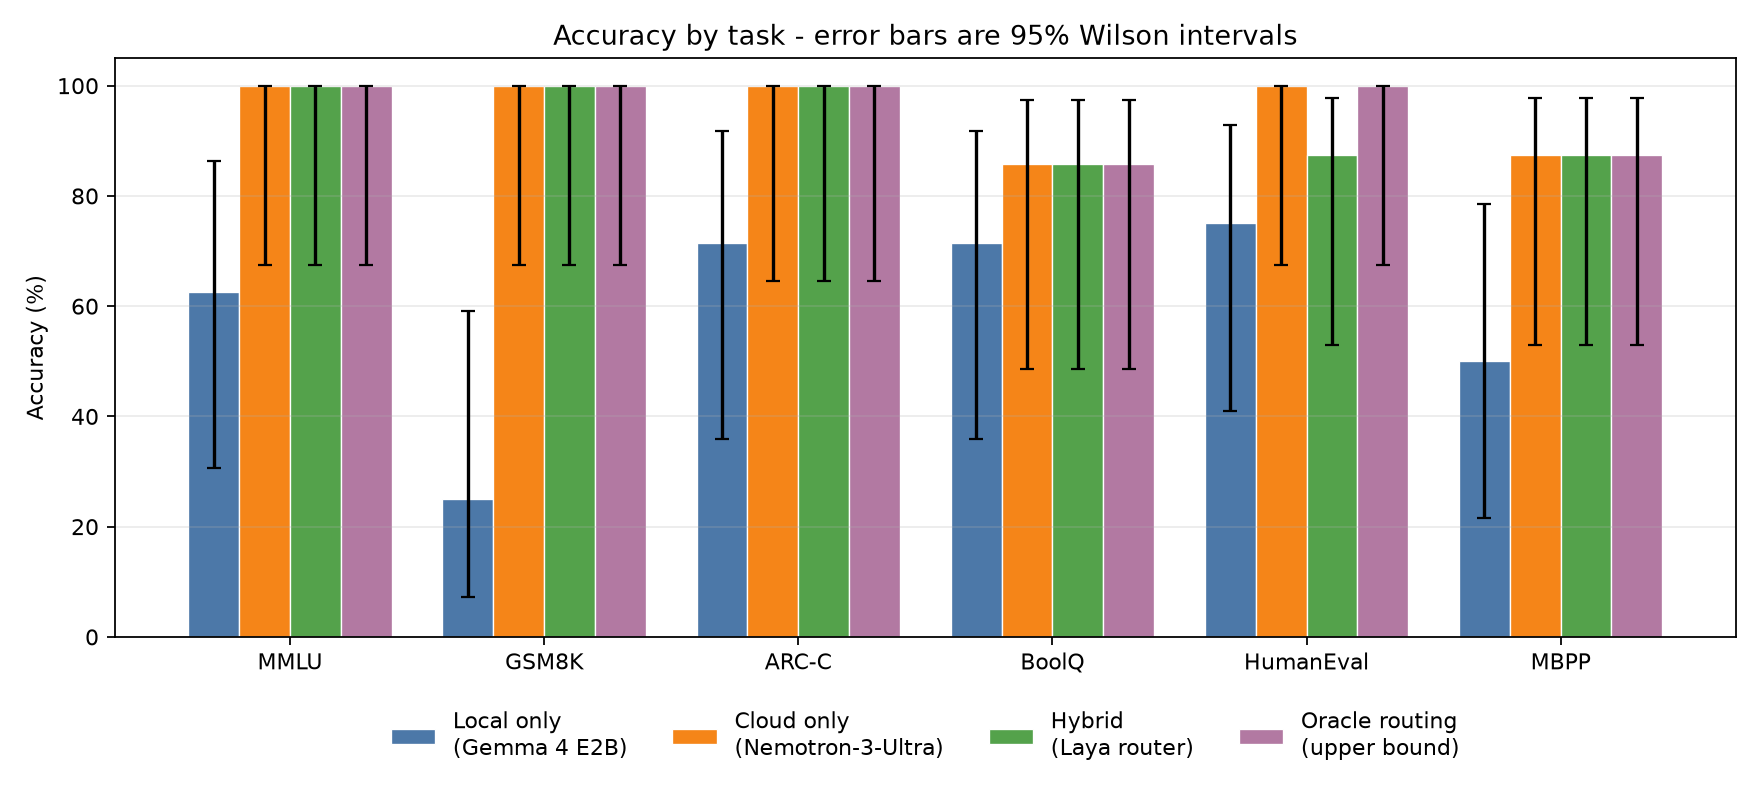

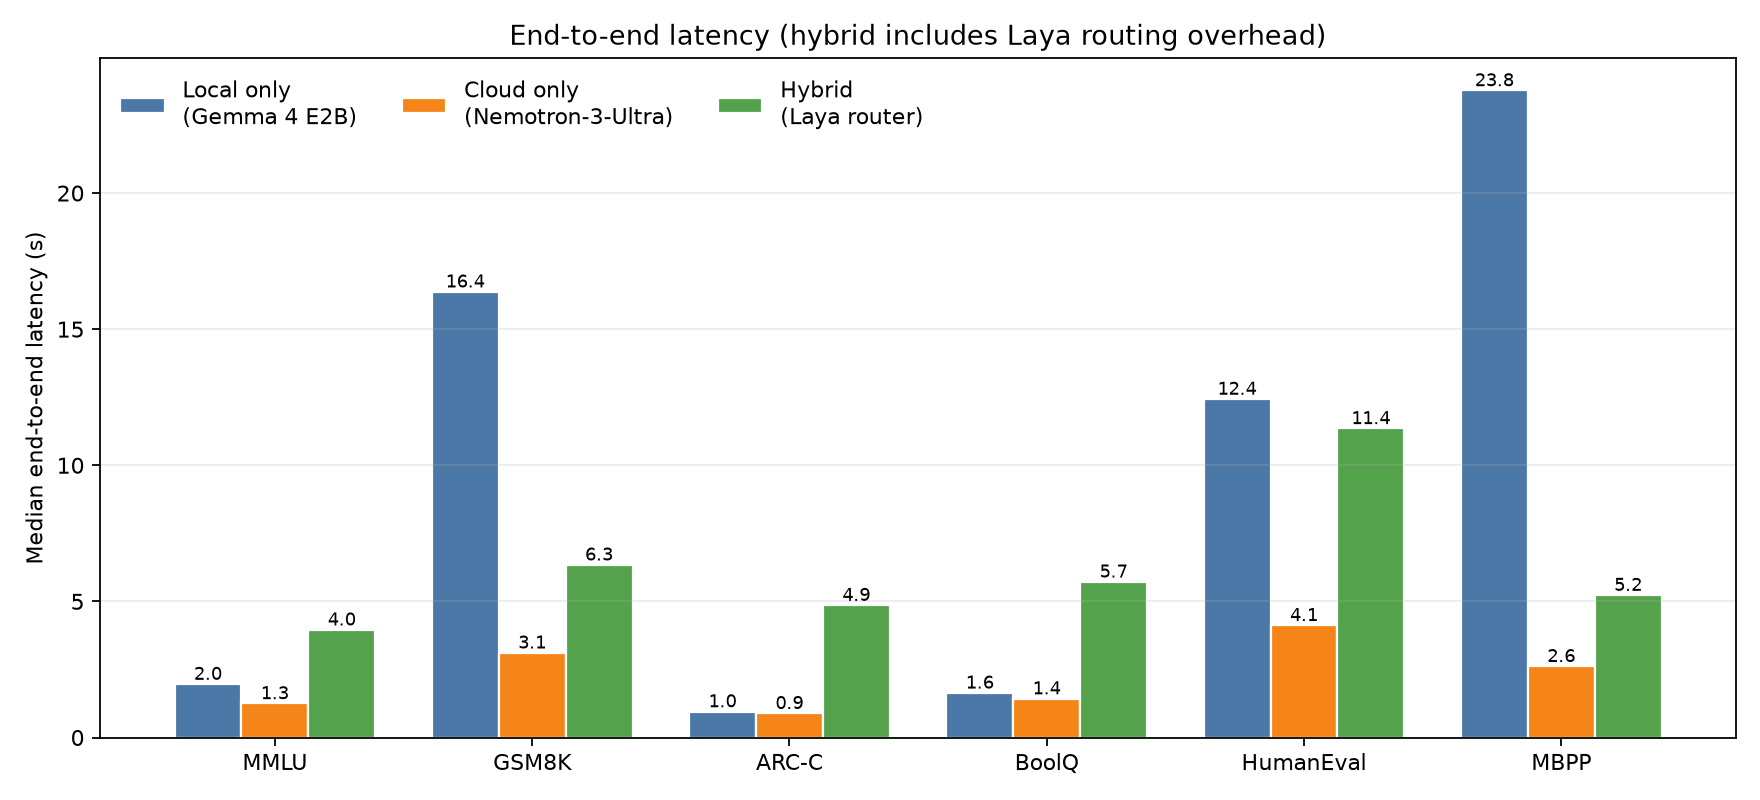

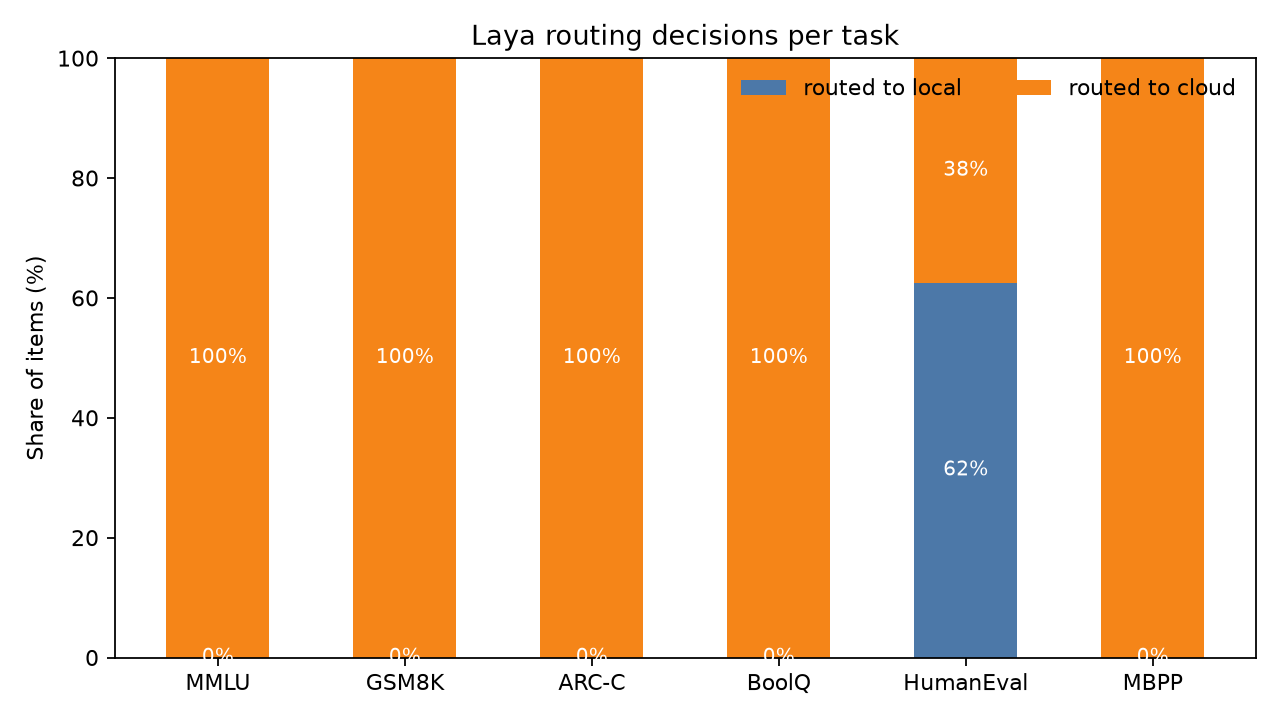

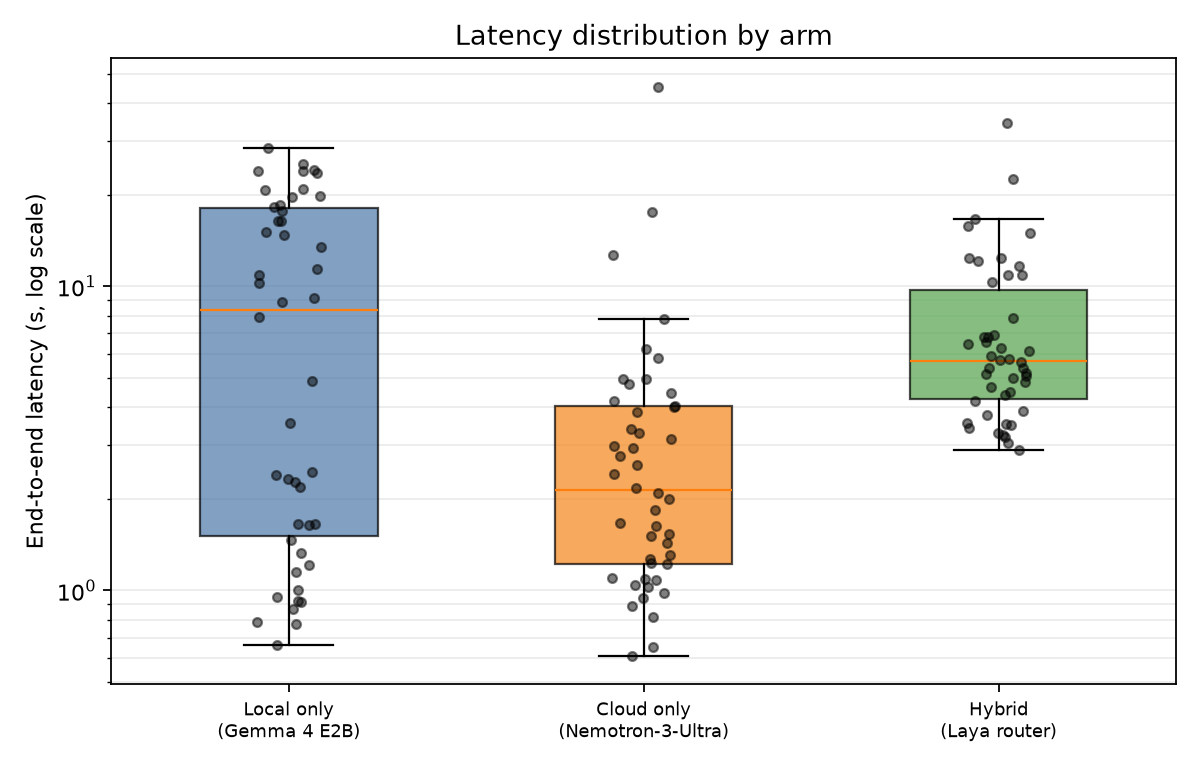

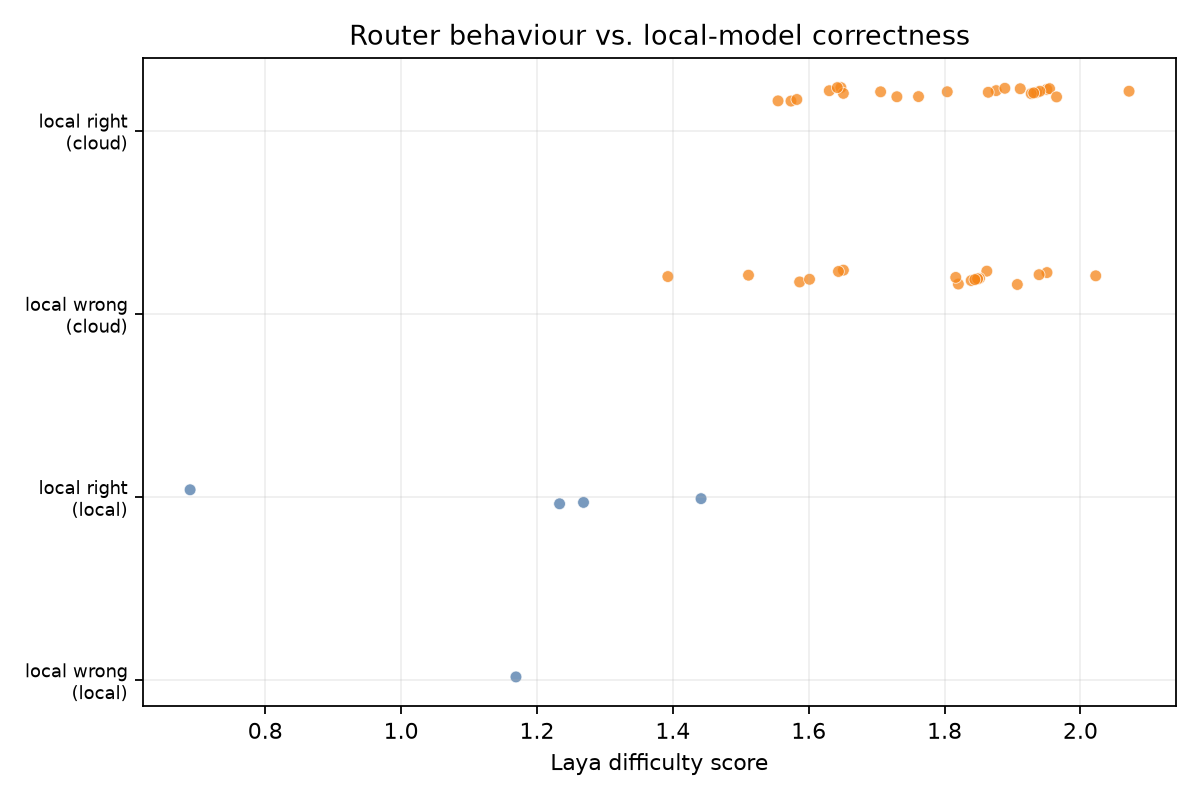

In [20]:
from IPython.display import Image, display as ipy_display

for path in figures:
    ipy_display(Image(filename=str(path)))

## 7. Findings

*(generated from the numbers above — re-run after the last evaluation day)*

In [21]:
lines = []
total_items = sum(c["n"] for c in summary["per_task"].values())
if total_items:
    def acc(arm):
        return sum(c[arm]["correct"] for c in summary["per_task"].values()) / total_items

    local_c = sum(c["local"]["correct"] for c in summary["per_task"].values())
    cloud_c = sum(c["cloud"]["correct"] for c in summary["per_task"].values())
    hybrid_c = sum(c["hybrid"]["correct"] for c in summary["per_task"].values())
    oracle_c = sum(c["oracle"]["correct"] for c in summary["per_task"].values())
    gap = (oracle_c - local_c) / total_items
    captured = (hybrid_c - local_c) / total_items

    total_out_tokens = sum(
        c.get("cloud_output_tokens_total", 0) for c in summary["per_task"].values()
    )
    local_med = np.median(
        [c["latency_ms"]["local"]["median"] for c in summary["per_task"].values()]
    )
    cloud_med = np.median(
        [c["latency_ms"]["cloud"]["median"] for c in summary["per_task"].values()]
    )
    hybrid_med = np.median(
        [c["latency_ms"]["hybrid"]["median"] for c in summary["per_task"].values()]
    )
    decision_med = np.median(
        [c["latency_ms"]["decision"]["median"] for c in summary["per_task"].values()]
    )
    routes = {}
    for cell in summary["per_task"].values():
        for route, count in cell["routes"].items():
            routes[route] = routes.get(route, 0) + count

    lines += [
        f"- **Sample**: {total_items} paired items across "
        f"{len(summary['per_task'])} tasks, on "
        f"{summary['host']['processor']} / {summary['host']['total_ram_gb']} GB RAM.",
        "",
        f"- **Accuracy**: local {acc('local'):.1%}, cloud {acc('cloud'):.1%}, "
        f"hybrid {acc('hybrid'):.1%}, oracle {acc('oracle'):.1%}.",
        f"- **Router quality**: Laya captures {captured / gap:.1%} of the accuracy "
        f"headroom a perfect router would unlock over always going local"
        if gap
        else "- **Router quality**: no headroom over the local arm on this sample.",
        f"- **Latency (median across tasks)**: local {local_med:.0f} ms, "
        f"cloud {cloud_med:.0f} ms, hybrid {hybrid_med:.0f} ms "
        f"(including {decision_med:.0f} ms of routing overhead).",
        f"- **Cloud compute used**: {total_out_tokens:,} output tokens across the study "
        f"({total_out_tokens / total_items:.1f} per item). This provider does not meter "
        "spend, so token volume is reported rather than dollars.",
        f"- **Routing split**: {routes.get('local', 0)} items to the local model, "
        f"{routes.get('cloud', 0)} to the cloud.",
        "",
    ]
print("\n".join(lines) if lines else "No results yet - run the evaluation cells above.")

- **Sample**: 46 paired items across 6 tasks, on Apple M2 / 16.0 GB RAM.

- **Accuracy**: local 58.7%, cloud 95.7%, hybrid 93.5%, oracle 95.7%.
- **Router quality**: Laya captures 94.1% of the accuracy headroom a perfect router would unlock over always going local
- **Latency (median across tasks)**: local 7198 ms, cloud 2022 ms, hybrid 5476 ms (including 2739 ms of routing overhead).
- **Cloud compute used**: 2,667 output tokens across the study (58.0 per item). This provider does not meter spend, so token volume is reported rather than dollars.
- **Routing split**: 5 items to the local model, 41 to the cloud.



## 8. Limitations and threats to validity

1. **Sample size.** The OpenRouter free tier allows 50 cloud requests per UTC
   day. The reported confidence intervals are wide by construction; the study
   is a pilot that should be extended over multiple days (the harness resumes
   and accumulates) or re-run with credits for a 1000/day cap.
2. **Single cloud model.** Only one cloud model is measured. A different cloud
   model would shift both the accuracy and the routing difficulty distribution,
   and Laya's thresholds were calibrated against this one.
3. **Derived hybrid arm.** The hybrid arm is derived from per-item backend
   results rather than executed independently. §5 validates the derivation on
   a subset, but the derived arm does not include second-order effects such as
   the router's own context-dependence.
4. **Reasoning disabled on the cloud model.** This equalises the arms, but it
   means the cloud accuracy is a *non-reasoning* accuracy and would rise with
   reasoning enabled.
5. **Strict multiple-choice extraction.** Only explicit answer markers count.
   This is fair across arms but under-credits models that answer correctly in
   prose.
6. **Generative scoring, not log-likelihood scoring.** Multiple-choice tasks
   ask the model to produce the answer, and the prompts carry an explicit
   answer directive (without it, small models pre-amble and score ~0).
   Published MMLU/ARC numbers use log-likelihood scoring, so absolute values
   here are not directly comparable to the literature. Relative comparisons
   between the three arms remain valid because they share byte-identical
   prompts.
7. **Sandboxed execution is a mitigation, not a security boundary.** The code
   sandbox applies rlimits and a timeout, but model-generated code still runs
   with the user's permissions on the host.
8. **Cloud latency is queue-dominated.** Shared inference endpoints sit behind
   queues, so measured cloud latency includes queueing that a reserved-capacity
   endpoint would not have. The latency comparison is therefore conservative
   against the cloud arm.
9. **Single machine, single run.** All local numbers come from one M2 MacBook
   Air with no other load. Thermal throttling on a fanless laptop can affect
   sustained throughput.

## 9. Reproducibility

* Fixed seed (`bench/config.py: SEED = 1234`) for every sample.
* Fixed few-shot exemplars shared by all arms.
* `temperature=0` on the cloud model; the local checkpoint's sampler is fixed
  at 0.0 by the `.litertlm` file.
* Every generation is appended to `results/raw_paired.jsonl` with its prompt
  text, so any table in this notebook can be recomputed from the raw log.
* `results/summary.json` holds the aggregated numbers behind every figure.

## 10. Citation

```bibtex
@misc{hybrid_chatbot_benchmark,
  title  = {A Cloud-Local Hybrid Chatbot: Intelligence and Hardware Trade-offs},
  note   = {Laya (System-1 routing) over Gemma 4 E2B (LiteRT-LM, Metal) and
            Nemotron-3-Ultra (OpenRouter)},
  year   = {2026}
}
```